Enter a decade from 1900 to 2000 (e.g., 1900):  1900


You selected: 1900


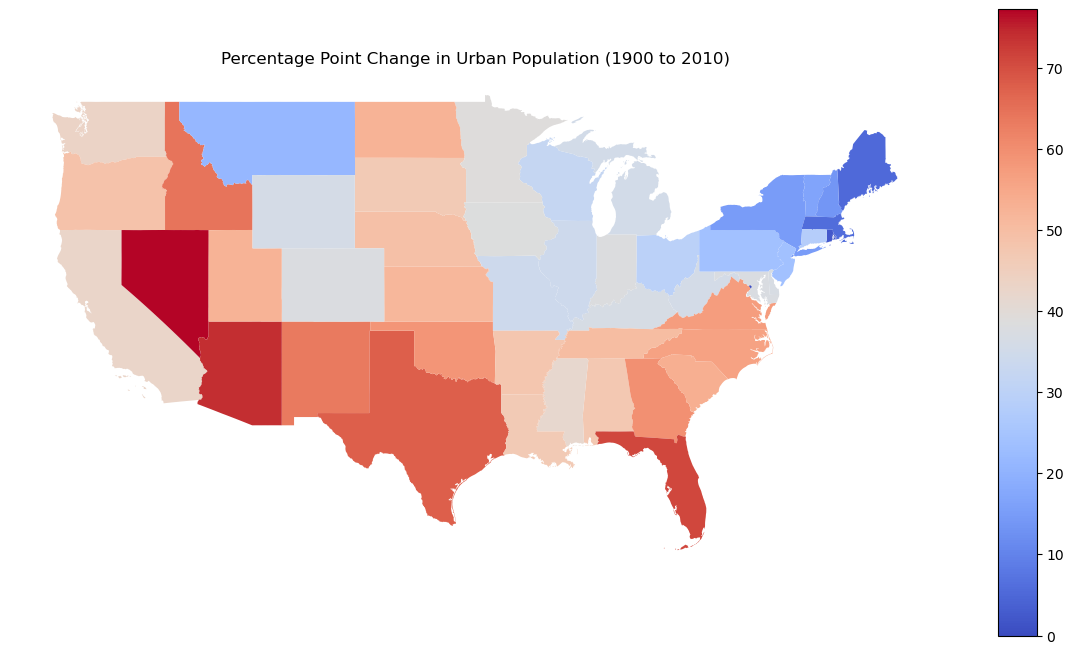

In [7]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import os

# Using current directory as working directory base
BASE_DIR = os.getcwd()

###### GETTING DECADE FOR MAP ######

# List of options
decades = ['1900', '1910', '1920', '1930', '1940', '1950', '1960', '1970', '1980', '1990', '2000']

# Prompting input
year = input("Enter a decade from 1900 to 2000 (e.g., 1900): ").strip()

# Checking whether input is a valid decade
if year in decades:
    print(f"You selected: {year}")
    decade = year
else:
    print("Invalid input. Please enter a decade between 1900 and 2000.")

# Loading data and state shapefiles
data_path = os.path.join(BASE_DIR, 'Maps_Project', 'data', 'urbanization', 'statedata.csv')
shapefile_path = os.path.join(BASE_DIR, 'Maps_Project', 'data', 'cb_2018_us_state_5m')
population_data = pd.read_csv(data_path)
shapefile_data = gpd.read_file(shapefile_path)

# Fixing errors in state and population data
population_data['Area Name'] = population_data['Area Name'].str.strip()
shapefile_data['NAME'] = shapefile_data['NAME'].str.strip()

# Filtering to exclude territories, Alaska, and Hawaii
continental_states = shapefile_data[~shapefile_data['STUSPS'].isin(['AK', 'HI', 'PR', 'VI', 'MP', 'GU', 'AS'])]

# Merging shapefile with urbanization data
merged = continental_states.merge(population_data, left_on='NAME', right_on='Area Name', how='inner')

# Calculating percent change in urban population in the specified decade
merged['pct_change'] = merged['2010'] - merged[f'{year}'] # Using final - initial to get raw change in percentage, not (f-i)/i * 100

# Mapping data
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
merged.plot(column='pct_change', cmap='coolwarm', legend=True, ax=ax)
plt.title(f'Percentage Point Change in Urban Population ({year} to 2010)')
plt.axis('off')
plt.show()